# The training set is not the population

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/sampling-bias-audit/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/sampling-bias-audit/demo.ipynb)

A credit model's training set was assembled with quotas: 30% group B and 40% rural, exactly as in the applicants
it will score. The usual representativeness check compares those two numbers and passes. This notebook audits the
cells instead, and measures what the miss costs the one cell it hit: rural B, whose bureau files understate their
real track record.

1. The engine
2. The audit: marginals pass, cells do not
3. What the miss costs, cell by cell
4. Two fixes: reweight, or collect
5. The chart
6. Try your own

## 1. The engine

Extracted from `audit.py` at build time. `sample` draws exact cell counts; `audit` computes training share /
population share for every marginal and every cell and flags a segment outside [0.80, 1.25] when the 99% Wilson
interval agrees; `fit` trains gradient boosting; `score` reports, per cell, the share of good payers the model
rejects on the deployment population. `study` runs the same three seeds as `evidence.py` (about 20 seconds), so the
numbers match `evidence.txt` exactly.

In [1]:
from __future__ import annotations

import warnings
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore", category=RuntimeWarning)

SEEDS = [199, 200, 201]


N_TRAIN = 20_000


N_POP = 60_000


FLAG_LO, FLAG_HI = 0.8, 1.25  # a segment is flagged when train share / population share leaves this band


Z = 2.576  # 99% Wilson interval on the training share


CELLS = ["A-urban", "A-rural", "B-urban", "B-rural"]


CURVE = [0, 50, 100, 200, 400, 900, 1900]  # rural-B rows added on top of the quota sample's 100


WORLD: Dict[str, float] = {
    "share_b": 0.30,
    "share_rural": 0.40,
    "thin_file": 1.5,  # how far rural B's recorded history understates the real one (sd)
    "noise": 0.8,
}


QUOTA: Dict[str, float] = {"A-urban": 0.305, "A-rural": 0.395, "B-urban": 0.295, "B-rural": 0.005}


EMPTY: Dict[str, float] = {"A-urban": 0.30, "A-rural": 0.40, "B-urban": 0.30, "B-rural": 0.0}


def pop_shares(w: Optional[Dict[str, float]] = None) -> Dict[str, float]:
    w = w or WORLD
    b, r = w["share_b"], w["share_rural"]
    return {"A-urban": (1 - b) * (1 - r), "A-rural": (1 - b) * r, "B-urban": b * (1 - r), "B-rural": b * r}


def draw_cell(
    cell: str, n: int, rng: np.random.Generator, w: Optional[Dict[str, float]] = None
) -> Dict[str, np.ndarray]:
    w = w or WORLD
    g, rural = int(cell[0] == "B"), int(cell.endswith("rural"))
    income = rng.normal(0, 1, n)
    record = rng.normal(0, 1, n)  # real track record
    history = record - w["thin_file"] * g * rural  # what the bureau file shows
    y = (0.9 * income + 0.9 * record + rng.normal(0, w["noise"], n) > -0.3).astype(int)
    return {
        "income": income,
        "history": history,
        "g": np.full(n, g),
        "rural": np.full(n, rural),
        "y": y,
        "cell": np.full(n, CELLS.index(cell)),
    }


def sample(
    shares: Dict[str, float],
    n: int,
    seed: int,
    w: Optional[Dict[str, float]] = None,
    extra: Optional[Dict[str, int]] = None,
) -> Dict[str, np.ndarray]:
    """Exact cell counts (round(share * n)) plus optional extra rows per cell."""
    rng = np.random.default_rng(seed)
    parts = [draw_cell(c, int(round(shares[c] * n)) + (extra or {}).get(c, 0), rng, w) for c in CELLS]
    return {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}


def wilson(k: int, n: int, z: float = Z) -> List[float]:
    if n == 0:
        return [0.0, 1.0]
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return [float(c - h), float(c + h)]


def audit(train: Dict[str, np.ndarray], target: Dict[str, float]) -> Dict[str, Dict[str, object]]:
    """Representation ratio = training share / population share for every marginal AND every cell. Flag when the
    ratio leaves [0.8, 1.25] AND the 99% Wilson interval on the training share excludes the population share, so a
    small segment is not flagged on noise alone."""
    n = len(train["y"])
    segs = {
        "group B": (train["g"] == 1, target["B-urban"] + target["B-rural"]),
        "region rural": (train["rural"] == 1, target["A-rural"] + target["B-rural"]),
    }
    for i, c in enumerate(CELLS):
        segs[c] = (train["cell"] == i, target[c])
    out = {}
    for name, (m, ps) in segs.items():
        k = int(m.sum())
        lo, hi = wilson(k, n)
        ratio = (k / n) / ps
        out[name] = {
            "rows": k,
            "train_share": k / n,
            "pop_share": ps,
            "ratio": ratio,
            "flag": bool((ratio < FLAG_LO or ratio > FLAG_HI) and not lo <= ps <= hi),
            "kind": "cell" if name in CELLS else "marginal",
        }
    return out


def fit(train: Dict[str, np.ndarray], weight: Optional[np.ndarray] = None) -> HistGradientBoostingClassifier:
    X = np.column_stack([train[c] for c in ("income", "history", "g", "rural")])
    return HistGradientBoostingClassifier(random_state=0).fit(X, train["y"], sample_weight=weight)


def score(model: HistGradientBoostingClassifier, d: Dict[str, np.ndarray]) -> Dict[str, Dict[str, float]]:
    """Per cell and overall: accuracy, and the share of good payers rejected (approve when p >= 0.5)."""
    X = np.column_stack([d[c] for c in ("income", "history", "g", "rural")])
    approve = model.predict_proba(X)[:, 1] >= 0.5
    out = {}
    for name, m in [("overall", np.ones(len(d["y"]), bool))] + [
        (c, d["cell"] == i) for i, c in enumerate(CELLS)
    ]:
        y, a = d["y"][m], approve[m]
        out[name] = {"acc": float((y == a).mean()), "good_rejected": float((~a[y == 1]).mean())}
    return out


def cell_weights(train: Dict[str, np.ndarray], target: Dict[str, float]) -> np.ndarray:
    n = len(train["y"])
    w = np.empty(n)
    for i, c in enumerate(CELLS):
        m = train["cell"] == i
        if m.any():  # an empty cell has no rows to weight: reweighting cannot reach it
            w[m] = target[c] / (m.sum() / n)
    return w


def one_seed(
    seed: int,
    w: Optional[Dict[str, float]] = None,
    quota: Optional[Dict[str, float]] = None,
    n_train: int = N_TRAIN,
    n_pop: int = N_POP,
    with_curve: bool = True,
) -> Dict[str, object]:
    ps = pop_shares(w)
    q = quota or QUOTA
    pop = sample(ps, n_pop, seed + 10_000, w)
    quota_set = sample(q, n_train, seed, w)
    prop_set = sample(ps, n_train, seed + 20_000, w)
    held = sample(
        q, n_pop // 4, seed + 30_000, w
    )  # the team's own test split: same process as the training set
    m_quota = fit(quota_set)
    res = {
        "audit": audit(quota_set, ps),
        "audit_control": audit(prop_set, ps),
        "quota_on_own_test": score(m_quota, held),
        "quota": score(m_quota, pop),
        "proportional": score(fit(prop_set), pop),
        "reweighted": score(fit(quota_set, cell_weights(quota_set, ps)), pop),
    }
    empty = sample(EMPTY, n_train, seed, w)
    res["empty"] = score(fit(empty), pop)
    res["empty_reweighted"] = score(fit(empty, cell_weights(empty, ps)), pop)
    if with_curve:
        res["curve"] = [
            score(fit(sample(q, n_train, seed, w, {"B-rural": k})), pop)["B-rural"]["good_rejected"]
            for k in CURVE
        ]
    return res


def study(seeds: Optional[List[int]] = None, w: Optional[Dict[str, float]] = None) -> Dict[str, object]:
    seeds = seeds or SEEDS
    per = [one_seed(s, w) for s in seeds]

    def agg(vals) -> Dict[str, float]:
        v = np.array(vals, float)
        return {"mean": float(v.mean()), "lo": float(v.min()), "hi": float(v.max())}

    def sc(key: str) -> Dict[str, Dict[str, Dict[str, float]]]:
        return {
            c: {m: agg([p[key][c][m] for p in per]) for m in ("acc", "good_rejected")} for c in per[0][key]
        }

    return {
        "seeds": seeds,
        "n_train": N_TRAIN,
        "n_pop": N_POP,
        "pop_shares": pop_shares(w),
        "quota_shares": QUOTA,
        "audit": per[0]["audit"],
        "audit_control": per[0]["audit_control"],
        "quota_on_own_test": sc("quota_on_own_test"),
        "quota": sc("quota"),
        "proportional": sc("proportional"),
        "reweighted": sc("reweighted"),
        "empty": sc("empty"),
        "empty_reweighted": sc("empty_reweighted"),
        "curve": [agg([p["curve"][i] for p in per]) for i in range(len(CURVE))],
    }


def parse_shares(text: str) -> Dict[str, float]:
    """`cell=share` overrides of QUOTA (e.g. "B-rural=0.06, A-rural=0.34"). Shares must sum to 1."""
    q = dict(QUOTA)
    for part in [p.strip() for p in text.split(",") if p.strip()]:
        if "=" not in part:
            raise ValueError(f"expected cell=share, got {part!r}")
        k, v = [x.strip() for x in part.split("=", 1)]
        if k not in QUOTA:
            raise ValueError(f"unknown cell {k!r}; known: {', '.join(CELLS)}")
        try:
            q[k] = float(v)
        except ValueError:
            raise ValueError(f"{k} needs a number, got {v!r}") from None
    if any(v < 0 for v in q.values()) or abs(sum(q.values()) - 1) > 1e-6:
        raise ValueError(f"cell shares must be non-negative and sum to 1 (they sum to {sum(q.values()):.3f})")
    return q

In [2]:
r = study()
print(f"study done: {len(r['seeds'])} seeds, training n = {r['n_train']:,}, deployment n = {r['n_pop']:,}")

study done: 3 seeds, training n = 20,000, deployment n = 60,000


## 2. The audit: marginals pass, cells do not

Both one-attribute checks read a ratio of 1.00. Rural B, 12.0% of the applicants, is 0.5% of the training set: 100
rows, a ratio of 0.04. A proportional sample of the same size raises no flag, so the audit is not flagging noise.

In [3]:
print(f"{'segment':<14} {'kind':<9} {'rows':>6} {'train':>7} {'population':>11} {'ratio':>6}  flag")
for name, v in r["audit"].items():
    print(
        f"{name:<14} {v['kind']:<9} {v['rows']:>6,} {v['train_share']:>7.1%} {v['pop_share']:>11.1%} {v['ratio']:>6.2f}  {'FLAG' if v['flag'] else 'ok'}"
    )
print(
    f"control (a proportional sample of the same size): {sum(v['flag'] for v in r['audit_control'].values())} segments flagged"
)

segment        kind        rows   train  population  ratio  flag
group B        marginal   6,000   30.0%       30.0%   1.00  ok
region rural   marginal   8,000   40.0%       40.0%   1.00  ok
A-urban        cell       6,100   30.5%       42.0%   0.73  FLAG
A-rural        cell       7,900   39.5%       28.0%   1.41  FLAG
B-urban        cell       5,900   29.5%       18.0%   1.64  FLAG
B-rural        cell         100    0.5%       12.0%   0.04  FLAG
control (a proportional sample of the same size): 0 segments flagged


## 3. What the miss costs, cell by cell

The model trained on the quota sample rejects 50.5% of rural B's good payers; trained on a proportional sample, 14.9%.
The other three cells do not move. The team's own test split, drawn the same way as the training set, reads 82.5%
accuracy; in deployment it is 80.8%. A 1.7-point drop is the whole signal an overall metric gives.

In [4]:
pct = lambda v: f"{v['mean']:.1%} [{v['lo']:.1%}-{v['hi']:.1%}]"
print(f"{'cell':<10} {'quota-trained':>22} {'proportional-trained':>22}")
for c in ["overall"] + CELLS:
    print(
        f"{c:<10} {pct(r['quota'][c]['good_rejected']):>22} {pct(r['proportional'][c]['good_rejected']):>22}"
    )
print(
    f"overall accuracy: the team's own test split {pct(r['quota_on_own_test']['overall']['acc'])}, deployment {pct(r['quota']['overall']['acc'])}, proportional-trained {pct(r['proportional']['overall']['acc'])}"
)

cell                quota-trained   proportional-trained
overall       18.1% [17.0%-19.0%]    14.0% [13.6%-14.8%]
A-urban       13.8% [13.4%-14.1%]    14.2% [13.4%-15.7%]
A-rural       13.8% [13.3%-14.2%]    14.0% [13.5%-14.3%]
B-urban       13.1% [12.4%-13.5%]    13.2% [12.8%-13.7%]
B-rural       50.5% [40.9%-58.0%]    14.9% [14.6%-15.4%]
overall accuracy: the team's own test split 82.5% [82.2%-82.8%], deployment 80.8% [80.5%-81.3%], proportional-trained 82.3% [82.2%-82.5%]


## 4. Two fixes: reweight, or collect

Reweighting the 100 rows up to their population share brings rural B's rejection to 21.0%, but it ranges 15.6% to
27.3% across seeds: 100 rows weighted 24x is a noisy fit. With no rural B rows at all the model rejects 64.6%, and
reweighting has nothing to weight. Collecting works: by 1,000 rows (5% of the set) the cell is at 17.3%.

In [5]:
print(
    f"reweight the 100 rows to the population cell shares: {pct(r['reweighted']['B-rural']['good_rejected'])}"
)
print(
    f"a training set with NO rural B rows: {pct(r['empty']['B-rural']['good_rejected'])}; reweighted: {pct(r['empty_reweighted']['B-rural']['good_rejected'])}"
)
print("collect more rural B rows (quota sample + k extra):")
for k, v in zip(CURVE, r["curve"]):
    print(f"  {100 + k:>5,} rural B rows: {pct(v)}")

reweight the 100 rows to the population cell shares: 21.0% [15.6%-27.3%]
a training set with NO rural B rows: 64.6% [63.5%-66.8%]; reweighted: 65.3% [63.9%-67.5%]
collect more rural B rows (quota sample + k extra):
    100 rural B rows: 50.5% [40.9%-58.0%]
    150 rural B rows: 44.7% [38.6%-50.1%]
    200 rural B rows: 32.8% [25.3%-40.1%]
    300 rural B rows: 29.1% [17.8%-41.9%]
    500 rural B rows: 24.5% [17.0%-30.2%]
  1,000 rural B rows: 17.3% [15.8%-18.3%]
  2,000 rural B rows: 15.7% [14.0%-17.1%]


## 5. The chart

The full figure, with the mechanism drawn, is `audit.png` (built by `make_chart.py` from `results.json`). Here, the
rows-needed curve.

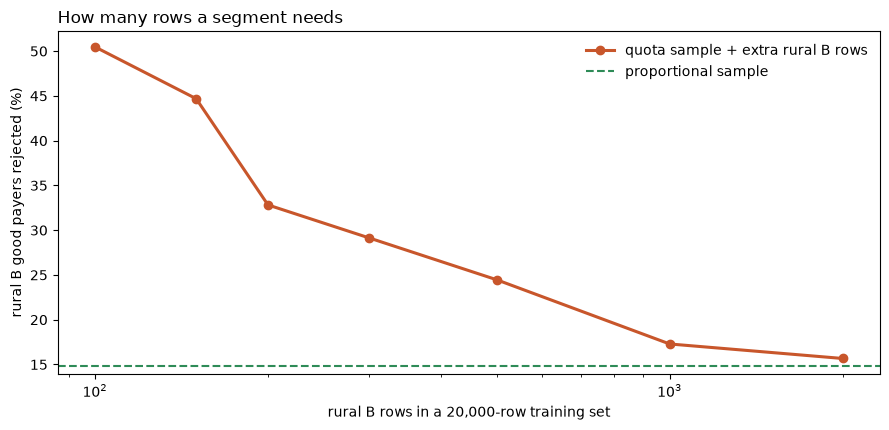

In [6]:
xs = [100 + k for k in CURVE]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(
    xs,
    [v["mean"] * 100 for v in r["curve"]],
    color="#c8562b",
    lw=2.2,
    marker="o",
    label="quota sample + extra rural B rows",
)
ax.axhline(
    r["proportional"]["B-rural"]["good_rejected"]["mean"] * 100,
    color="#2e8b57",
    ls="--",
    label="proportional sample",
)
ax.set_xscale("log")
ax.set_xlabel("rural B rows in a 20,000-row training set")
ax.set_ylabel("rural B good payers rejected (%)")
ax.set_title("How many rows a segment needs", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- A quota on each attribute matches every marginal and says nothing about the cells: rural B fell from 12% to 0.5%.
- Audit the cells (the intersections you will deploy on), with an interval, not just each attribute.
- The cost lands on one cell: 50.5% of its good payers rejected vs 14.9%, while overall accuracy moves 1.7 points.
- Reweighting a thin cell helps but is noisy; an empty cell cannot be reweighted. About 1,000 rows fixed it here.

## 6. Try your own

In [7]:
# A quota sample where rural B is 3% - is that enough?
# q = parse_shares("A-urban=0.33, A-rural=0.37, B-urban=0.27, B-rural=0.03")
# x = one_seed(1, quota=q, n_pop=20_000, with_curve=False); print(x["quota"]["B-rural"], x["proportional"]["B-rural"])

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version takes your own
training-set shares: `pip install -r requirements.txt && streamlit run app.py`.

Sibling builds: [`disparate-impact`](../disparate-impact) found that fixing B's data beat every threshold, and assumed
you could get it; this build measures how much of it you need.